# 07 · Evaluation and Explainability
**Test year 2025** is touched exactly once here, together with the **2022-2025 walk-forward backtest**.

Metrics (`src/heatwave_peak/metrics.py`):
* **accuracy**: MAE, RMSE, MAPE, R², bias
* **peak risk**: under-forecast rate, mean / P95 / max shortfall, **reserve-breach rate** (share of days short by more than 3 % of the peak,
  which is beyond India's typical secondary + tertiary reserve margin)
* **cost**: stylised Rs crore/day (Rs 10/kWh shortfall, Rs 2.5/kWh surplus, 4-hour peak window)

Regimes: all days · ordinary · **heatwave** (>= 20 % of demand in heatwave states) · **critical peak** (above the rolling P90).

In [1]:
# --- common setup ------------------------------------------------------------
# The project code lives in src/heatwave_peak (installed with `pip install -e .`).
# If it is not installed, fall back to adding src/ to the import path.
import sys, warnings
from pathlib import Path
try:
    import heatwave_peak
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import heatwave_peak
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from heatwave_peak import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    """Save the current figure to reports/figures/<name>.png."""
    plt.savefig(C.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

In [2]:
from heatwave_peak import metrics as M, experiment as EX
test = pd.read_parquet(C.PROCESSED_DIR / "predictions_test_2025.parquet")
bt = pd.read_parquet(C.PROCESSED_DIR / "predictions_backtest_2022_2025.parquet")
valid = pd.read_parquet(C.PROCESSED_DIR / "predictions_valid_2024.parquet")
NAMES = {"naive_lag7": "Naive (last week)", "lgbm_l2": "LGBM-L2", "lgbm_quantile60": "LGBM-Quantile0.6",
         "lgbm_quantile80": "LGBM-Quantile0.8",
         "lgbm_prototype": "LGBM-Prototype", "lgbm_linex": "LGBM-LINEX (no heat)", "lgbm_halo": "LGBM-HALO (ours)"}
cols = {NAMES[k]: f"pred_{k}" for k in EX.MODEL_ORDER}
ev = lambda df: M.compare_models(df[df.target_imputed == 0], cols)
show = ["model", "n_days", "MAE_MW", "RMSE_MW", "MAPE_pct", "R2", "bias_MW", "under_rate_pct", "mean_shortfall_MW",
        "p95_shortfall_MW", "max_shortfall_MW", "reserve_breach_pct", "cost_crore_per_day"]
tm, bm = ev(test), ev(bt)

## 1. Test year 2025: all days

In [3]:
tm[tm.regime == "all"][show].set_index("model").round(2)

,n_days,MAE_MW,RMSE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,p95_shortfall_MW,max_shortfall_MW,reserve_breach_pct,cost_crore_per_day
model,,,,,,,,,,,,
Naive (last week),355.0,7593.24,10170.79,3.57,0.34,-571.38,53.80,7587.54,17097.11,31181.67,25.63,19.84
LGBM-L2,355.0,2462.07,3428.31,1.16,0.93,-151.25,55.21,2366.65,4699.03,12360.76,1.13,6.38
LGBM-Quantile0.6,355.0,2517.55,3831.25,1.20,0.91,724.06,43.94,2040.66,4169.11,7558.97,0.85,5.21
LGBM-Quantile0.8,355.0,3133.64,4766.40,1.50,0.86,2141.63,28.17,1760.81,3022.76,7961.22,0.28,4.62
LGBM-Prototype,355.0,2572.57,3605.90,1.22,0.92,205.17,51.27,2308.86,4699.58,12138.43,1.13,6.12
LGBM-LINEX (no heat),355.0,2535.75,3767.25,1.21,0.91,232.25,50.99,2258.96,4888.65,11244.69,1.13,5.99
LGBM-HALO (ours),355.0,2709.05,4098.99,1.29,0.89,915.32,41.69,2151.26,4156.53,8466.92,1.13,5.40


## 2. Test year 2025: by regime

In [4]:
for reg in ["ordinary", "heatwave", "critical_peak"]:
    print(f"--- {reg} ---")
    display(tm[tm.regime == reg][show].set_index("model").round(2))

--- ordinary ---


,n_days,MAE_MW,RMSE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,p95_shortfall_MW,max_shortfall_MW,reserve_breach_pct,cost_crore_per_day
model,,,,,,,,,,,,
Naive (last week),341.0,7206.62,9633.73,3.42,0.38,-142.34,52.79,6961.09,14480.92,28101.22,23.46,18.23
LGBM-L2,341.0,2444.44,3404.39,1.16,0.92,-118.82,54.84,2337.08,4598.74,12360.76,0.88,6.29
LGBM-Quantile0.6,341.0,2500.57,3824.42,1.20,0.90,780.35,43.40,1981.74,4062.60,7391.47,0.59,5.08
LGBM-Quantile0.8,341.0,3118.07,4781.02,1.50,0.85,2184.76,27.86,1675.04,3022.32,5237.46,0.00,4.52
LGBM-Prototype,341.0,2546.70,3572.97,1.21,0.92,263.13,50.73,2250.57,4688.85,12138.43,0.88,5.97
LGBM-LINEX (no heat),341.0,2515.06,3750.01,1.20,0.91,286.57,50.44,2209.06,4870.83,11244.69,0.88,5.86
LGBM-HALO (ours),341.0,2695.79,4090.29,1.29,0.89,946.70,41.06,2130.14,3904.02,8466.92,0.88,5.32


--- heatwave ---


,n_days,MAE_MW,RMSE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,p95_shortfall_MW,max_shortfall_MW,reserve_breach_pct,cost_crore_per_day
model,,,,,,,,,,,,
Naive (last week),14.0,17010.30,19039.70,7.37,-2.89,-11021.55,78.57,17838.45,30178.32,31181.67,78.57,59.06
LGBM-L2,14.0,2891.51,3966.54,1.28,0.83,-941.21,64.29,2981.01,6121.61,8191.50,7.14,8.64
LGBM-Quantile0.6,14.0,2930.97,3994.02,1.29,0.83,-646.90,57.14,3130.64,5453.27,7558.97,7.14,8.30
LGBM-Quantile0.8,14.0,3512.85,4395.18,1.56,0.79,1091.12,35.71,3390.43,4513.61,7961.22,7.14,7.15
LGBM-Prototype,14.0,3202.71,4331.36,1.40,0.80,-1206.40,64.29,3429.30,6167.56,8676.36,7.14,9.82
LGBM-LINEX (no heat),14.0,3039.71,4165.11,1.34,0.81,-1090.84,64.29,3212.64,5845.63,8660.15,7.14,9.24
LGBM-HALO (ours),14.0,3032.04,4305.36,1.34,0.80,150.96,57.14,2520.94,6082.84,7778.59,7.14,7.35


--- critical_peak ---


,n_days,MAE_MW,RMSE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,p95_shortfall_MW,max_shortfall_MW,reserve_breach_pct,cost_crore_per_day
model,,,,,,,,,,,,
Naive (last week),45.0,8040.33,11132.09,3.44,-8.80,-7440.47,84.44,9166.27,24749.66,31181.67,44.44,31.26
LGBM-L2,45.0,2522.20,3355.43,1.09,0.11,-1933.08,73.33,3037.69,6266.44,12360.76,4.44,9.21
LGBM-Quantile0.6,45.0,2227.57,2825.26,0.96,0.37,-1332.54,71.11,2503.20,5420.60,7558.97,4.44,7.57
LGBM-Quantile0.8,45.0,1878.72,2435.40,0.81,0.53,-94.50,55.56,1775.90,3983.71,7961.22,2.22,4.84
LGBM-Prototype,45.0,2564.83,3373.29,1.10,0.10,-1603.41,73.33,2841.99,6082.44,12138.43,4.44,8.82
LGBM-LINEX (no heat),45.0,2560.88,3361.15,1.10,0.11,-1734.16,68.89,3117.37,6175.55,11244.69,4.44,9.00
LGBM-HALO (ours),45.0,2217.38,2730.15,0.95,0.41,-679.18,60.00,2413.80,5112.14,7778.59,2.22,6.56


## 3. Walk-forward backtest 2022-2025 (4 test years, expanding training window)

In [5]:
for reg in ["all", "ordinary", "heatwave", "critical_peak"]:
    print(f"--- {reg} ---")
    display(bm[bm.regime == reg][show].set_index("model").round(2))

--- all ---


,n_days,MAE_MW,RMSE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,p95_shortfall_MW,max_shortfall_MW,reserve_breach_pct,cost_crore_per_day
model,,,,,,,,,,,,
Naive (last week),1451.0,7606.26,10247.70,3.81,0.60,-287.47,55.27,7140.77,17253.79,38804.44,24.81,19.45
LGBM-L2,1451.0,2634.28,3808.91,1.32,0.94,18.75,53.34,2451.63,5019.92,23127.76,2.89,6.56
LGBM-Quantile0.6,1451.0,2729.51,4124.99,1.38,0.94,677.50,46.59,2202.26,4439.54,15115.32,1.59,5.81
LGBM-Quantile0.8,1451.0,3354.44,5132.81,1.71,0.90,2218.33,30.81,1843.95,3042.52,10353.32,0.55,5.06
LGBM-Prototype,1451.0,2702.52,3910.12,1.36,0.94,410.73,49.90,2296.54,4704.62,20200.31,2.21,6.14
LGBM-LINEX (no heat),1451.0,2672.41,3957.43,1.35,0.94,217.12,52.38,2343.84,4799.43,18813.80,2.55,6.36
LGBM-HALO (ours),1451.0,2780.91,4141.56,1.40,0.93,847.00,43.35,2230.60,4279.53,10816.26,1.79,5.68


--- ordinary ---


,n_days,MAE_MW,RMSE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,p95_shortfall_MW,max_shortfall_MW,reserve_breach_pct,cost_crore_per_day
model,,,,,,,,,,,,
Naive (last week),1320.0,7435.30,10066.90,3.76,0.59,125.11,53.94,6776.30,16086.71,36326.25,22.88,18.40
LGBM-L2,1320.0,2563.88,3698.57,1.30,0.94,62.01,53.11,2355.54,4868.51,23127.76,2.50,6.32
LGBM-Quantile0.6,1320.0,2675.20,4068.74,1.37,0.93,729.61,46.44,2094.77,4164.99,15115.32,1.29,5.59
LGBM-Quantile0.8,1320.0,3306.59,5121.44,1.70,0.89,2233.81,30.68,1748.24,2925.26,10353.32,0.38,4.92
LGBM-Prototype,1320.0,2634.22,3810.72,1.34,0.94,413.35,50.15,2214.16,4604.59,20200.31,1.89,5.97
LGBM-LINEX (no heat),1320.0,2604.59,3870.47,1.32,0.94,256.30,52.27,2246.19,4702.03,18813.80,2.20,6.13
LGBM-HALO (ours),1320.0,2696.89,4039.49,1.37,0.93,782.74,43.71,2189.50,4215.50,10816.26,1.67,5.57


--- heatwave ---


,n_days,MAE_MW,RMSE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,p95_shortfall_MW,max_shortfall_MW,reserve_breach_pct,cost_crore_per_day
model,,,,,,,,,,,,
Naive (last week),131.0,9328.90,11917.41,4.29,0.38,-4444.75,68.70,10024.16,21256.48,38804.44,44.27,29.99
LGBM-L2,131.0,3343.59,4780.73,1.59,0.90,-417.12,55.73,3374.33,8048.70,10472.55,6.87,8.98
LGBM-Quantile0.6,131.0,3276.68,4654.02,1.55,0.91,152.50,48.09,3248.16,5899.07,9848.89,4.58,7.96
LGBM-Quantile0.8,131.0,3836.55,5246.08,1.83,0.88,2062.39,32.06,2766.85,4359.24,8789.74,2.29,6.50
LGBM-Prototype,131.0,3390.80,4798.10,1.61,0.90,384.40,47.33,3176.12,6782.24,10183.81,5.34,7.90
LGBM-LINEX (no heat),131.0,3355.80,4745.56,1.59,0.90,-177.70,53.44,3306.35,6873.14,9595.37,6.11,8.66
LGBM-HALO (ours),131.0,3627.43,5056.39,1.73,0.89,1494.56,39.69,2686.60,5189.77,8478.89,3.05,6.83


--- critical_peak ---


,n_days,MAE_MW,RMSE_MW,MAPE_pct,R2,bias_MW,under_rate_pct,mean_shortfall_MW,p95_shortfall_MW,max_shortfall_MW,reserve_breach_pct,cost_crore_per_day
model,,,,,,,,,,,,
Naive (last week),344.0,6782.80,9527.39,3.14,0.61,-5002.33,76.45,7707.39,20751.51,38804.44,34.01,24.46
LGBM-L2,344.0,2453.67,3161.04,1.15,0.96,-1393.03,68.90,2791.70,5786.99,12360.76,4.36,8.22
LGBM-Quantile0.6,344.0,2305.43,2977.76,1.08,0.96,-967.32,64.24,2547.12,5638.69,8873.24,2.33,7.21
LGBM-Quantile0.8,344.0,2224.36,3009.33,1.05,0.96,355.48,47.67,1960.05,3974.33,8516.76,0.58,5.03
LGBM-Prototype,344.0,2437.42,3159.23,1.14,0.96,-1014.07,66.28,2603.76,5386.11,12138.43,3.49,7.61
LGBM-LINEX (no heat),344.0,2449.88,3160.09,1.15,0.96,-1277.30,68.60,2716.42,5640.70,11244.69,3.49,8.04
LGBM-HALO (ours),344.0,2370.18,3065.99,1.11,0.96,-235.09,55.81,2333.89,4972.86,8478.89,2.03,6.28


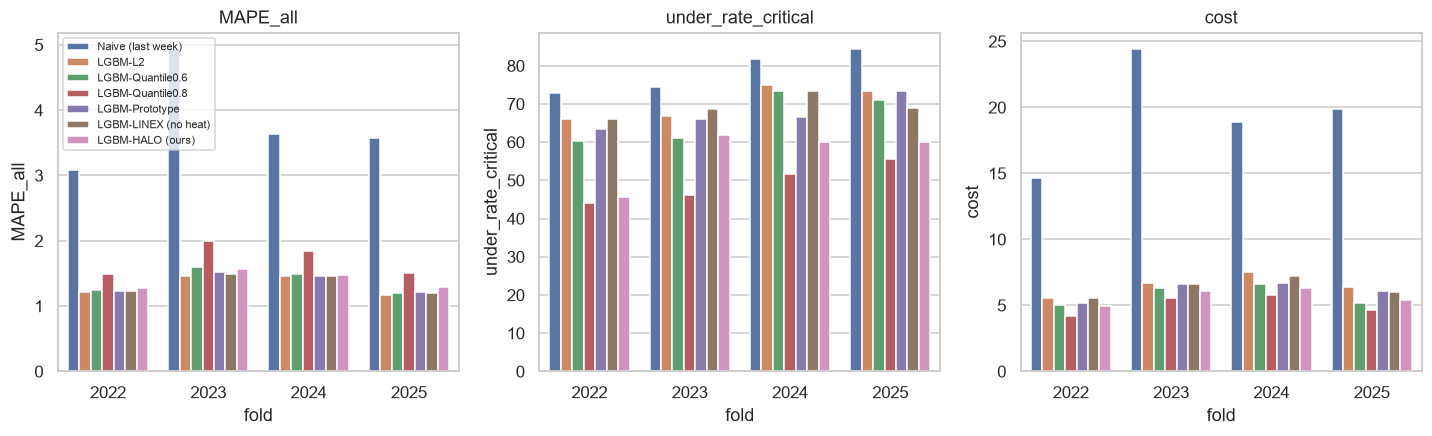

fold,2022,2023,2024,2025
model,,,,
LGBM-HALO (ours),1.28,1.56,1.48,1.29
LGBM-L2,1.22,1.46,1.45,1.16
LGBM-LINEX (no heat),1.23,1.49,1.46,1.21
LGBM-Prototype,1.23,1.52,1.47,1.22
LGBM-Quantile0.6,1.24,1.60,1.49,1.20
LGBM-Quantile0.8,1.49,2.00,1.85,1.50
Naive (last week),3.08,4.94,3.63,3.57


In [6]:
per_fold = []
for y, g in bt[bt.target_imputed == 0].groupby("fold"):
    for name, col in cols.items():
        m_all = M.regime_metrics(g.peak_mw, g[col])
        hw = g[g.national_hw_regime == 1]; cp = g[g.is_critical_peak == 1]
        per_fold.append({"fold": y, "model": name, "MAPE_all": m_all["MAPE_pct"],
                         "under_rate_heat": M.regime_metrics(hw.peak_mw, hw[col]).get("under_rate_pct", np.nan),
                         "under_rate_critical": M.regime_metrics(cp.peak_mw, cp[col]).get("under_rate_pct", np.nan),
                         "cost": m_all["cost_crore_per_day"]})
pf = pd.DataFrame(per_fold)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a_, m in zip(ax, ["MAPE_all", "under_rate_critical", "cost"]):
    sns.barplot(data=pf, x="fold", y=m, hue="model", ax=a_); a_.legend_.remove(); a_.set_title(m)
ax[0].legend(fontsize=7, loc="upper left"); savefig("07_backtest_by_fold"); plt.show()
pf.pivot(index="model", columns="fold", values="MAPE_all").round(2)

## 4. Accuracy versus safety trade-off

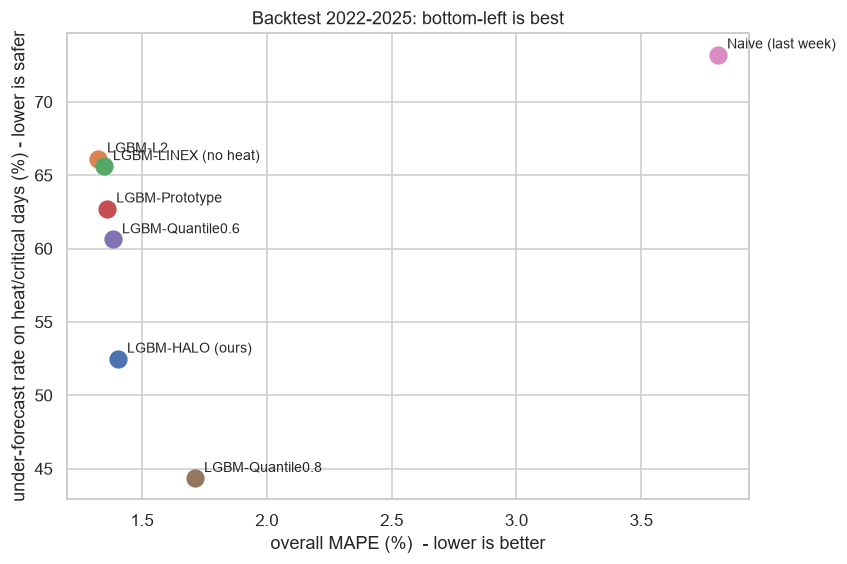

In [7]:
agg = bm[bm.regime.isin(["all", "heatwave_or_critical"])].pivot(index="model", columns="regime")
fig, ax = plt.subplots(figsize=(8, 5.5))
for mname in agg.index:
    x, y = agg.loc[mname, ("MAPE_pct", "all")], agg.loc[mname, ("under_rate_pct", "heatwave_or_critical")]
    ax.scatter(x, y, s=120); ax.annotate(mname, (x, y), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set(xlabel="overall MAPE (%)  - lower is better", ylabel="under-forecast rate on heat/critical days (%) - lower is safer",
       title="Backtest 2022-2025: bottom-left is best")
savefig("07_accuracy_vs_safety"); plt.show()

## 5. Case studies: the 2024 record heatwave and the June 2025 heatwave

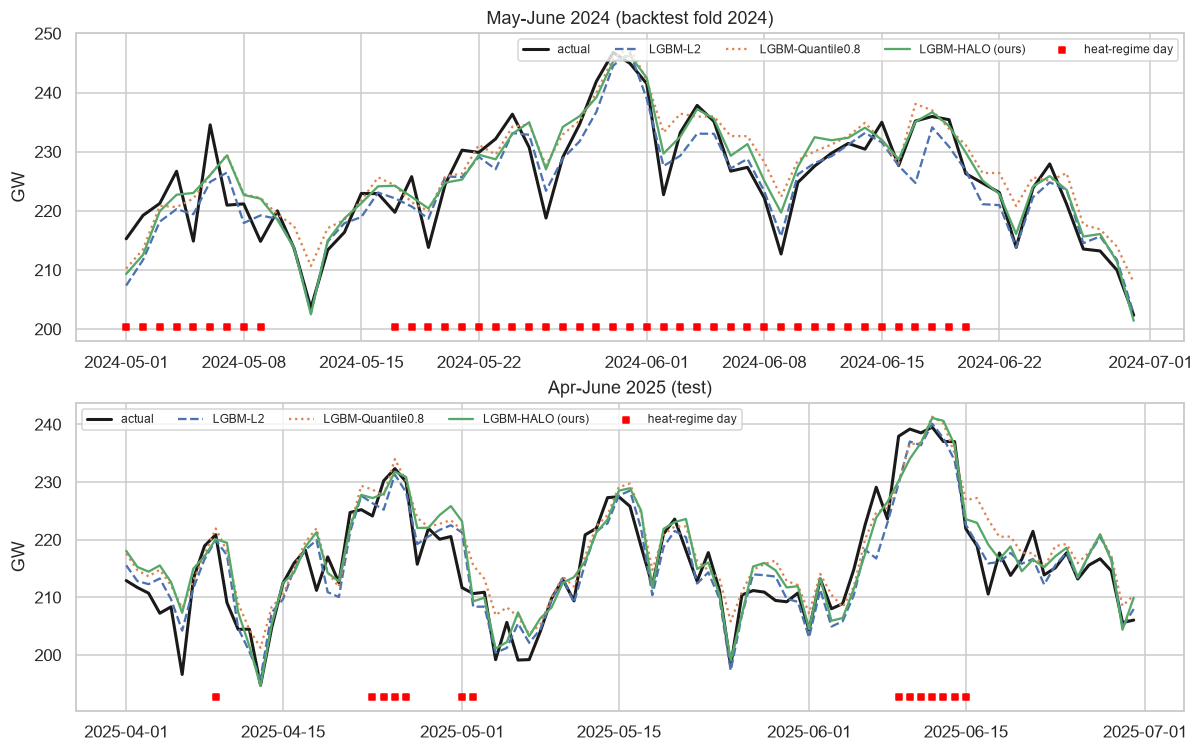

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8))
for a_, (df, s, e_, ttl) in zip(ax, [(bt[bt.fold == 2024], "2024-05-01", "2024-06-30", "May-June 2024 (backtest fold 2024)"),
                                     (test, "2025-04-01", "2025-06-30", "Apr-June 2025 (test)")]):
    d = df.loc[s:e_]
    a_.plot(d.index, d.peak_mw / 1e3, "k-", lw=2, label="actual")
    for k, st in [("lgbm_l2", "--"), ("lgbm_quantile80", ":"), ("lgbm_halo", "-")]:
        a_.plot(d.index, d[f"pred_{k}"] / 1e3, st, label=NAMES[k])
    hwd = d[d.national_hw_regime == 1]
    a_.scatter(hwd.index, np.full(len(hwd), d.peak_mw.min() / 1e3 - 2), marker="s", color="red", s=12, label="heat-regime day")
    a_.set(ylabel="GW", title=ttl); a_.legend(fontsize=8, ncol=5)
savefig("07_case_studies"); plt.show()

In [9]:
d = bt[bt.fold == 2024].loc["2024-05-26":"2024-06-01"]
out = pd.DataFrame({"actual_GW": d.peak_mw / 1e3, "heat_exposure": d.heat_exposure})
for k in ["lgbm_l2", "lgbm_quantile80", "lgbm_halo"]:
    out[NAMES[k] + " error_GW"] = (d[f"pred_{k}"] - d.peak_mw) / 1e3
out.round(2)

,actual_GW,heat_exposure,LGBM-L2 error_GW,LGBM-Quantile0.8 error_GW,LGBM-HALO (ours) error_GW
date,,,,,
2024-05-26,218.79,0.65,4.60,8.94,8.23
2024-05-27,229.08,0.56,-0.22,3.85,5.12
2024-05-28,234.64,0.54,-2.89,0.62,1.37
2024-05-29,241.90,0.59,-5.16,-1.90,-2.72
2024-05-30,246.78,0.70,-2.23,-0.95,-1.51
2024-05-31,244.94,0.81,1.88,2.75,1.35
2024-06-01,241.52,0.85,-2.55,0.54,0.97


## 6. Error distributions by regime

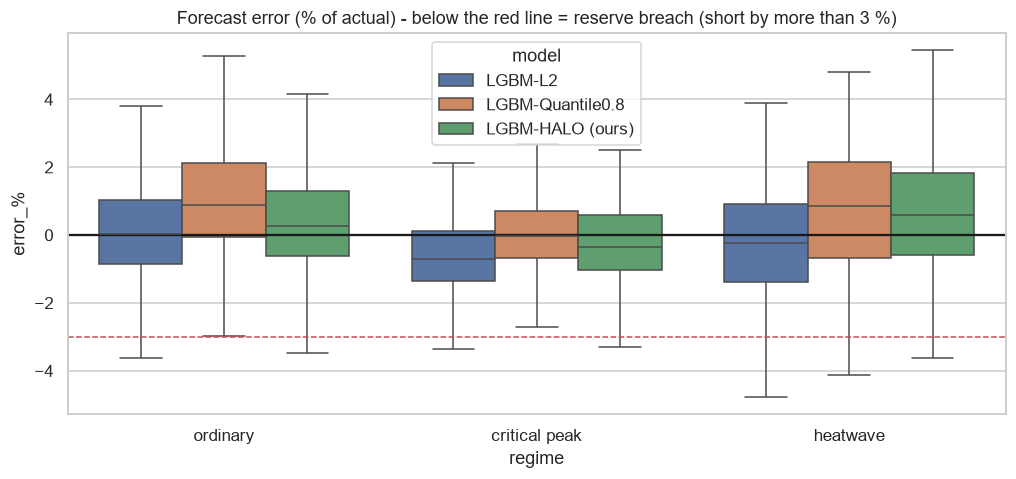

In [10]:
long = []
for k in ["lgbm_l2", "lgbm_quantile80", "lgbm_halo"]:
    e = 100 * (bt[f"pred_{k}"] - bt.peak_mw) / bt.peak_mw
    long.append(pd.DataFrame({"error_%": e, "model": NAMES[k], "regime": np.where(bt.national_hw_regime == 1, "heatwave",
                              np.where(bt.is_critical_peak == 1, "critical peak", "ordinary"))}))
long = pd.concat(long)
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=long, x="regime", y="error_%", hue="model", showfliers=False)
plt.axhline(0, color="k"); plt.axhline(-3, color="r", ls="--", lw=1)
plt.title("Forecast error (% of actual) - below the red line = reserve breach (short by more than 3 %)"); savefig("07_error_by_regime"); plt.show()

## 7. Explainability: SHAP contributions (LightGBM `pred_contrib`)
LightGBM computes exact TreeSHAP contributions natively (`pred_contrib=True`), so no extra library is needed.
We compare **what pushes the forecast up** on heatwave days for L2 versus HALO.

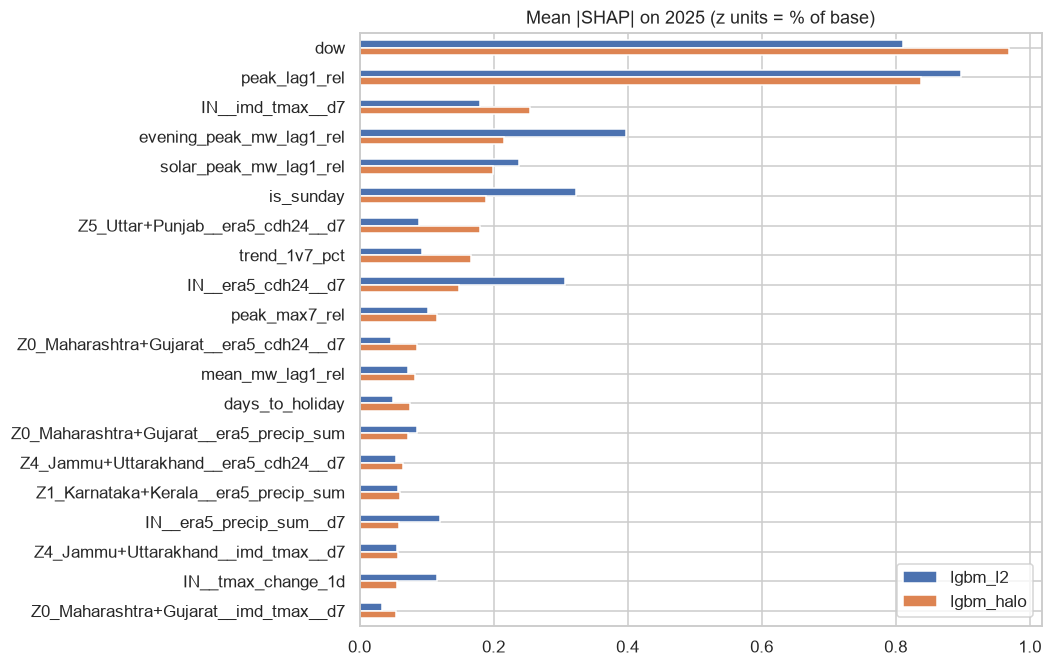

In [11]:
import lightgbm as lgb
tab = pd.read_parquet(C.PROCESSED_DIR / "model_table.parquet")
from heatwave_peak import models as MD
tab, _ = MD.add_loss_side_info(tab)
feats = [f for f in __import__("heatwave_peak.features", fromlist=["x"]).feature_columns(tab) if f not in ("loss_severity", "loss_scarcity")]
X = tab.loc[C.TEST_START:C.TEST_END, feats]
boost = {k: lgb.Booster(model_file=str(C.MODELS_DIR / f"{k}.txt")) for k in ["lgbm_l2", "lgbm_halo"]}
contrib = {k: pd.DataFrame(b.predict(X, pred_contrib=True)[:, :-1], index=X.index, columns=feats) for k, b in boost.items()}
imp = pd.DataFrame({k: v.abs().mean() for k, v in contrib.items()}).sort_values("lgbm_halo", ascending=False)
imp.head(20).plot.barh(figsize=(8, 7)); plt.gca().invert_yaxis(); plt.title("Mean |SHAP| on 2025 (z units = % of base)")
savefig("07_shap_importance"); plt.show()

In [12]:
hw_idx = tab.loc[C.TEST_START:C.TEST_END].query("national_hw_regime == 1").index
heat_feats = [f for f in feats if any(s in f for s in ("heat", "tmax", "ehf", "cdh", "hw_", "severity", "run_length", "night"))]
summary = pd.DataFrame({k: {"heat-related SHAP on heatwave days (% of base)": v.loc[hw_idx, heat_feats].sum(axis=1).mean(),
                            "heat-related SHAP on ordinary days": v.drop(hw_idx)[heat_feats].sum(axis=1).mean()} for k, v in contrib.items()})
summary.round(3)

,lgbm_l2,lgbm_halo
heat-related SHAP on heatwave days (% of base),-0.104,0.257
heat-related SHAP on ordinary days,-0.056,-0.052


## 8. Research criteria check (same criteria as the prototype, now on real data)

In [13]:
def crit(df_metrics, label):
    g = df_metrics.set_index(["model", "regime"])
    l2, ha = NAMES["lgbm_l2"], NAMES["lgbm_halo"]
    drop_hw = g.loc[(l2, "heatwave_or_critical"), "under_rate_pct"] - g.loc[(ha, "heatwave_or_critical"), "under_rate_pct"]
    ord_deg = 100 * (g.loc[(ha, "ordinary"), "MAE_MW"] / g.loc[(l2, "ordinary"), "MAE_MW"] - 1)
    cost_red = 100 * (1 - g.loc[(ha, "all"), "cost_crore_per_day"] / g.loc[(l2, "all"), "cost_crore_per_day"])
    breach = (g.loc[(l2, "heatwave_or_critical"), "reserve_breach_pct"], g.loc[(ha, "heatwave_or_critical"), "reserve_breach_pct"])
    print(f"[{label}]")
    print(f"  C1 under-forecast rate on heat/critical days: {g.loc[(l2,'heatwave_or_critical'),'under_rate_pct']:.1f}% -> {g.loc[(ha,'heatwave_or_critical'),'under_rate_pct']:.1f}%  (drop {drop_hw:.1f} pts)")
    print(f"  C2 ordinary-day MAE change vs L2: {ord_deg:+.2f}%   (tolerance <= +5%)")
    print(f"  C3 reserve-breach rate on heat/critical days: {breach[0]:.1f}% -> {breach[1]:.1f}%")
    print(f"  C4 stylised grid cost reduction vs L2: {cost_red:.1f}%")
    print(f"  overall MAPE: L2 {g.loc[(l2,'all'),'MAPE_pct']:.2f}%  HALO {g.loc[(ha,'all'),'MAPE_pct']:.2f}%")
crit(tm, "TEST 2025"); crit(bm, "BACKTEST 2022-2025")
tm.to_csv(C.METRICS_DIR / "metrics_test_2025_named.csv", index=False); bm.to_csv(C.METRICS_DIR / "metrics_backtest_named.csv", index=False)

[TEST 2025]
  C1 under-forecast rate on heat/critical days: 71.2% -> 57.7%  (drop 13.5 pts)
  C2 ordinary-day MAE change vs L2: +10.28%   (tolerance <= +5%)
  C3 reserve-breach rate on heat/critical days: 3.8% -> 1.9%
  C4 stylised grid cost reduction vs L2: 15.4%
  overall MAPE: L2 1.16%  HALO 1.29%
[BACKTEST 2022-2025]
  C1 under-forecast rate on heat/critical days: 66.1% -> 52.5%  (drop 13.6 pts)
  C2 ordinary-day MAE change vs L2: +5.19%   (tolerance <= +5%)
  C3 reserve-breach rate on heat/critical days: 4.7% -> 2.1%
  C4 stylised grid cost reduction vs L2: 13.4%
  overall MAPE: L2 1.32%  HALO 1.40%
